# Lab 04: How to write the agent loop

## Goal

Write the loop that turns one tool call into an agent: call the model, run the tools it asks for, send the results
back, and repeat until the model answers or a turn cap stops it. The moment comes at the end. Typed without its
accent, "Helena Holy" gets an empty list from our exact-match lookup, and the agent usually stops with a fluent "I
couldn't find a customer ..." without trying another spelling. The loop records that as a finished answer. One change to what
the tool returns, a list of close names, lets the agent find her in four turns.

## What you will learn

- How to turn the tool-call round trip into a loop that stops on `finish_reason` or on a turn cap, and why it needs
  both.
- How to record each turn: the tools called and the prompt tokens of every call, which grow because the whole list is
  sent again.
- How ReAct (a thought, an action and an observation written as text) differs from native tool calls on the same
  question, and what each costs.
- How to return a tool's error to the model as a result, instead of letting it crash the loop.
- Why reliability falls with every turn, with 0.95 to the power n worked for 1, 3, 6 and 10 turns.
- How to design a tool result that helps the model recover from a near miss.

## Where this lab starts

Lab 03 ran one tool call by hand. Its round trip had three steps:

1. **Send** the messages and the tool schemas. The model does not run anything: it replies with `tool_calls`, each
   one a tool name and a JSON string of arguments, and `finish_reason` says `tool_calls`.
2. **Run and append.** Our code runs each requested function, then appends the assistant message that holds the
   calls and one `tool` message per call, carrying the result and the call's `id`.
3. **Send again.** The model reads the results and answers in text, and `finish_reason` says `stop`.

Lab 03 knew in advance that one round trip was enough. In general we do not: a question may need one round trip or
five, and only the model's reply tells us whether another is needed. So the three steps go in a loop. This lab
restates everything it uses, so it runs on its own.

The picture below is the loop we will write, on the stations of the agent loop: the request, the context (the
messages list), the model deciding, our code checking and running the tool, the result appended, and the two exits.
The black box is the model's work; the lime boxes are our code's.

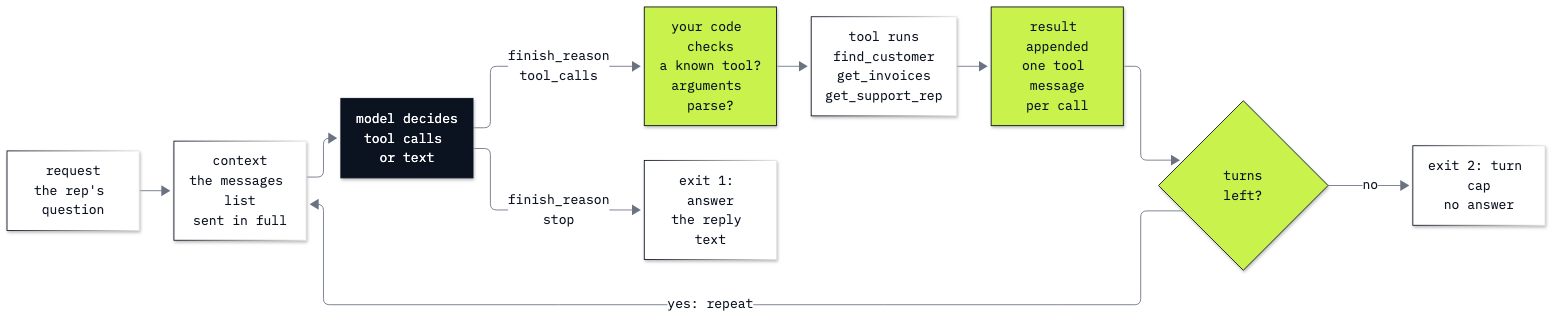

In [1]:
from IPython.display import Image

Image("resources/lab04_agent_loop.png", width=760)

Notice that our code sits on every path out of the model. The model only decides between asking for tools and
writing text; whether a tool runs, what gets appended and when the loop gives up are ours.

---

## Setup

The config cell is the same in every lab: it finds the repository folder by `models.env`, reads the model and the
prices from there, and finds your key without printing it (Lab 00 reads it line by line).

In [2]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, the client and the two settings every call in this lab shares. `MAX_OUTPUT` caps each reply at 300 tokens,
far more than a tool call or a two-sentence answer needs. The prices (US dollars per million tokens) come from
`models.env`, so Part B can say what each call cost.

In [3]:
from openai import OpenAI, omit

client = OpenAI()
MAX_OUTPUT = 300
PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
print("input:", PRICE_IN, "| output:", PRICE_OUT, "US dollars per million tokens")

input: 0.1 | output: 0.5 US dollars per million tokens


Every call below passes `reasoning_effort=EFFORT or omit`. `omit` is the OpenAI library's marker for "leave this
argument out of the request": when `models.env` sets no effort (a model without a reasoning setting), `EFFORT` is
`None` and the request goes without `reasoning_effort` instead of sending an empty value the API rejects. With
`none`, as here, tools work on Chat Completions. This lab uses Chat Completions throughout, as the fundamental; the frameworks in
later labs run the same loop on OpenAI's newer Responses API.

---

## Part A: Turn the round trip into an agent loop

An agent is the round trip repeated until the model stops asking for tools. Before we write the loop, we need the
lookups it can call, described as tools, and one turn run by hand, so we know exactly what the loop repeats.

### The three lookups on the shop's database

The shop's data is `data/chinook.db`, a SQLite file with a `customers`, an `invoices` and an `employees` table. We
open it read-only (`mode=ro` in the connection's URI), so no tool in this lab can change it, and with
`check_same_thread=False` so the connection can also be used from other threads, which some frameworks in later labs
run tools on. Each lookup is a plain Python function that
runs one SQL query:

- `find_customer(name)` matches the full name exactly (`FirstName || ' ' || LastName` joins the two columns with a
  space) and returns a **list**, because two customers could share a name. An empty list means no exact match.
- `get_invoices(customer_id)` counts the customer's invoices and adds up their totals.
- `get_support_rep(customer_id)` joins the customer to the employee who looks after them. If no customer has that id
  it raises a `ValueError`; Part E needs that line.

In [4]:
import json
import sqlite3

DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name):
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id):
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id):
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName, e.Email FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    if row is None:
        raise ValueError(f"no customer with id {customer_id}")
    return {"customer_id": customer_id, "support_rep": row[0], "email": row[1]}

Before any model is involved, we call the three lookups ourselves for the question this lab asks, about the customer
Helena Holý. These printed values are the right answers that every run below is checked against.

In [5]:
print(find_customer("Helena Holý"))
print(get_invoices(6))
print(get_support_rep(6))

[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson', 'email': 'steve@chinookcorp.com'}


Reading the three results:

- `find_customer` returned a list with one dictionary: Helena Holý is customer **6**, in the Czech Republic.
- `get_invoices(6)` says **7 invoices** adding up to **49.62** US dollars.
- `get_support_rep(6)` names **Steve Johnson**.

Notice the order: the second and third lookups need the `customer_id` that only the first one returns. Whoever
answers the question, a person or a model, has to call `find_customer` first and wait for its result. That
dependency is why this question needs more than one round trip.

### The tools the model sees

The model never sees our functions, only their descriptions. Each description is a JSON schema in Chat Completions'
tool format, the same shape Lab 03 wrote: a name, a description the model reads to decide when to call it, and the
parameters. `strict: True` asks the API to make the arguments match the schema exactly, which needs every property in
`required` and `additionalProperties: False`. The three schemas differ only in name, description and parameters, so
a small function writes the shape once.

In [6]:
def tool_schema(name, description, properties):
    return {
        "type": "function",
        "function": {
            "name": name,
            "description": description,
            "strict": True,
            "parameters": {
                "type": "object",
                "properties": properties,
                "required": list(properties),
                "additionalProperties": False,
            },
        },
    }


TOOLS = [
    tool_schema("find_customer", "Find a shop customer by full name. Returns a list of matches with their customer_id.",
                {"name": {"type": "string", "description": "First and last name, for example 'Ana Silva'"}}),
    tool_schema("get_invoices", "Count a customer's invoices and add up their total in US dollars.",
                {"customer_id": {"type": "integer"}}),
    tool_schema("get_support_rep", "Name the support rep who looks after a customer.",
                {"customer_id": {"type": "integer"}}),
]
print(json.dumps(TOOLS[0], indent=2))

{
  "type": "function",
  "function": {
    "name": "find_customer",
    "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
    "strict": true,
    "parameters": {
      "type": "object",
      "properties": {
        "name": {
          "type": "string",
          "description": "First and last name, for example 'Ana Silva'"
        }
      },
      "required": [
        "name"
      ],
      "additionalProperties": false
    }
  }
}


That is the whole of what the model knows about `find_customer`: its name, one sentence of description and one
string argument. `list(properties)` turns the dictionary of properties into the list of their names, so every
argument is required, as strict mode needs.

The other half of "your code checks" is a dictionary from tool names to the Python functions allowed to run. A name
the model sends that is not a key here never runs anything.

In [7]:
FUNCTIONS = {
    "find_customer": find_customer,
    "get_invoices": get_invoices,
    "get_support_rep": get_support_rep,
}

SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")
QUESTION = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
print(list(FUNCTIONS))

['find_customer', 'get_invoices', 'get_support_rep']


The system message says "never answer from memory" for a reason: Chinook is a public sample database, and a model
may have seen Helena's numbers in its training data. We want every fact to come from a lookup we can check.

### One turn by hand

The first step of the round trip: send the system message and the question, with the tools.

In [8]:
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

response = client.chat.completions.create(
    model=MODEL,
    messages=messages,
    tools=TOOLS,
    max_completion_tokens=MAX_OUTPUT,
    reasoning_effort=EFFORT or omit,
)
choice = response.choices[0]
print("finish_reason:", choice.finish_reason)
print("content:      ", choice.message.content)
for call in choice.message.tool_calls or []:
    print("tool call:    ", call.id, call.function.name, call.function.arguments)

finish_reason: tool_calls
content:       None
tool call:     call_WKEHN3X97eHuv6VTSg7XyUF8 find_customer {"name":"Helena Holý"}


`finish_reason` is `tool_calls` and `content` is `None`: the model wrote no text. It asked for one tool,
`find_customer` with the arguments `{"name":"Helena Holý"}`. It did not ask for the invoices or the rep yet, because it has no `customer_id` to pass. Its
`arguments` is a JSON **string**, not a dictionary, and its `id` is what the result must carry back.

Running a call is the same three moves for every tool, so one small function does it: look the name up in
`FUNCTIONS`, turn the argument string into a dictionary with `json.loads`, and call the function with `**arguments`
(which passes each key of the dictionary as a keyword argument: `find_customer(name="Helena Holý")`). The result goes
back as a string, because a `tool` message's content is text; `ensure_ascii=False` keeps "Holý" readable instead of
writing it as `Hol\u00fd`.

In [9]:
def run_tool(call):
    function = FUNCTIONS[call.function.name]
    arguments = json.loads(call.function.arguments)
    result = function(**arguments)
    return json.dumps(result, ensure_ascii=False)


messages.append(choice.message)
for call in choice.message.tool_calls:
    result = run_tool(call)
    print(call.function.name, "->", result)
    messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

print([m["role"] if isinstance(m, dict) else m.role for m in messages])

find_customer -> [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
['system', 'user', 'assistant', 'tool']


The list now holds four messages: the system message and the question we wrote, the assistant message the API
returned (the library's own message object; we append it as it came, and the library accepts it beside our
dictionaries), and our `tool` message with Helena's record.

We could call `create` again by hand, as Lab 03 did. But how many times? This question needs a second round trip
(the invoices and the rep) and then a third call for the answer; another question might need one call or six. So the
repeat goes in a loop.

### The loop

Each pass of the loop is one call to the model, which we call a **turn**:

1. Send the whole list, with the tools.
2. Append the reply to the list, whatever it is.
3. If `finish_reason` is not `tool_calls`, the model has written its reply: leave the loop (the first exit).
4. Otherwise run every tool call, append one `tool` message per call, and go back to step 1.

`for turn in range(1, MAX_TURNS + 1)` is the turn cap: after six turns the loop ends whatever the model wants (the
second exit, which Part C looks at). We start again from a fresh list, so this run does not reuse the turn above.

In [10]:
MAX_TURNS = 6
messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": QUESTION},
]

for turn in range(1, MAX_TURNS + 1):
    response = client.chat.completions.create(
        model=MODEL,
        messages=messages,
        tools=TOOLS,
        max_completion_tokens=MAX_OUTPUT,
        reasoning_effort=EFFORT or omit,
    )
    choice = response.choices[0]
    messages.append(choice.message)
    print(f"turn {turn}: finish_reason = {choice.finish_reason}")

    if choice.finish_reason != "tool_calls":
        print("answer:", choice.message.content)
        break

    for call in choice.message.tool_calls:
        result = run_tool(call)
        print(f"    {call.function.name}({call.function.arguments}) -> {result}")
        messages.append({"role": "tool", "tool_call_id": call.id, "content": result})

turn 1: finish_reason = tool_calls
    find_customer({"name":"Helena Holý"}) -> [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


turn 2: finish_reason = tool_calls
    get_invoices({"customer_id": 6}) -> {"customer_id": 6, "invoice_count": 7, "total": 49.62}
    get_support_rep({"customer_id": 6}) -> {"customer_id": 6, "support_rep": "Steve Johnson", "email": "steve@chinookcorp.com"}


turn 3: finish_reason = stop
answer: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Read the run turn by turn:

- **Turn 1:** one call, `find_customer`, as in the hand turn. The loop ran it and went round again.
- **Turn 2:** two calls in one reply, `get_invoices` and `get_support_rep`, both with `customer_id` 6, the id that turn 1's result gave it.
- **Turn 3:** `finish_reason` is `stop`, and the reply is the answer: *Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.*

Every fact in that sentence matches the lookups we ran ourselves (7 invoices, 49.62, Steve Johnson). Notice what
turn 2 shows: when two calls depend only on what the model already has, it can ask for both in one reply, and our
`for call in ...` runs them in order. That saved a turn.

**Checkpoint A.** Three turns: `find_customer`, then `get_invoices` and `get_support_rep` together, then the answer
with 7 invoices, 49.62 US dollars and Steve Johnson. The loop left by its first exit, an answer. A pass here shows
the loop runs every requested call and stops on text; it does not yet show what each turn cost, or what happens when
the cap is hit.

---

## Part B: Measure how the context grows each turn

Each turn sends the whole list again, so a turn's cost depends on every turn before it. To see that, we record each
turn as it happens. From here on Parts C to F run the same loop with other questions, caps and tools, so we put it in
a function, `run_agent`, that does exactly what the loop above did and also records, for each turn:

- `messages_sent`: how many messages were in the list sent on that call;
- `prompt_tokens`: the tokens of everything sent, read from `response.usage` (the system message, the question, the
  three tool schemas and every message appended since);
- `completion_tokens`: the tokens of the reply (a tool call's JSON or the answer's text).

It returns four things: the answer (or `None`), why it stopped, the list of turn records and the final messages list.

In [11]:
def run_agent(question, max_turns=MAX_TURNS):
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}]
    turns = []
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=TOOLS,
            max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
        )
        choice = response.choices[0]
        turns.append({
            "turn": turn,
            "finish_reason": choice.finish_reason,
            "messages_sent": len(messages),
            "prompt_tokens": response.usage.prompt_tokens,
            "completion_tokens": response.usage.completion_tokens,
            "tool_calls": [f"{c.function.name}({c.function.arguments})" for c in choice.message.tool_calls or []],
        })
        messages.append(choice.message)
        if choice.finish_reason != "tool_calls":
            return choice.message.content, choice.finish_reason, turns, messages
        for call in choice.message.tool_calls:
            messages.append({"role": "tool", "tool_call_id": call.id, "content": run_tool(call)})
    return None, "turn cap", turns, messages

Two helpers read the records: `print_turns` prints one row per turn, and `run_cost` adds up the tokens and prices
them, input tokens at the input price and output tokens at the output price.

In [12]:
def print_turns(turns):
    print(f"{'turn':>4}  {'finish_reason':13}  {'sent':>4}  {'prompt':>6}  {'output':>6}  tool calls")
    for t in turns:
        calls = ", ".join(t["tool_calls"]) or "-"
        print(f"{t['turn']:>4}  {t['finish_reason']:13}  {t['messages_sent']:>4}  "
              f"{t['prompt_tokens']:>6}  {t['completion_tokens']:>6}  {calls}")


def run_cost(turns):
    prompt = sum(t["prompt_tokens"] for t in turns)
    output = sum(t["completion_tokens"] for t in turns)
    return prompt, output, prompt / 1_000_000 * PRICE_IN + output / 1_000_000 * PRICE_OUT


answer, stop_reason, helena_turns, helena_messages = run_agent(QUESTION)
print_turns(helena_turns)
print("stopped by:", stop_reason, "|", answer)

turn  finish_reason  sent  prompt  output  tool calls
   1  tool_calls        2     259      20  find_customer({"name":"Helena Holý"})
   2  tool_calls        4     316      51  get_invoices({"customer_id": 6}), get_support_rep({"customer_id": 6})
   3  stop              7     431      24  -
stopped by: stop | Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Each column, in plain words:

- **sent:** 2, 4 and 7 messages. Turn 1 sends the system message and the question; turn 2 adds the assistant's call
  and its result; turn 3 adds the second assistant message and its two results.
- **prompt:** 259, 316 and 431 tokens. Even turn 1, with two short messages, costs 259 tokens, because the three tool
  schemas travel with every call. Each later turn adds what was appended since.
- **output:** 20, 51 and 24 tokens: a short tool call, then two calls, then the answer.

Now add the turns up.

In [13]:
prompt, output, dollars = run_cost(helena_turns)
print(f"input tokens paid for: {prompt} (the last call alone sent {helena_turns[-1]['prompt_tokens']})")
print(f"output tokens: {output}")
print(f"cost of this run: ${dollars:.6f}")

input tokens paid for: 1006 (the last call alone sent 431)
output tokens: 95
cost of this run: $0.000148


The total cost is the sum over turns of input tokens times the input price plus output tokens times the output
price:

$$\text{cost} = \sum_{\text{turns}} \left( \frac{\text{prompt}}{10^6} \times 0.10 + \frac{\text{output}}{10^6} \times 0.50 \right)$$

Here that is 1,006 input tokens and 95 output tokens:

$$\frac{1006}{10^6} \times 0.10 + \frac{95}{10^6} \times 0.50 = 0.0001006 + 0.0000475 \approx 0.000148 \text{ dollars}$$

about fifteen thousandths of a cent for the run.

The point is the first number: we paid for 1,006 input tokens, although the longest call sent only
431. **Every call pays again for everything before it**, so the system message and the tool schemas
were billed three times. A loop of ten turns pays for its start ten times, which is why later labs work on what goes
into the list (lab 05). These prompts are under 1,024 tokens, too short for OpenAI's prompt caching, so no cached
price applies here.

**Checkpoint B.** Prompt tokens rising every turn (ours: 259, 316 and 431), messages sent 2, 4 and 7, and a total input
count larger than any single call. A pass shows the list is resent in full; it does not say the growth is a problem
yet, at three turns and a fraction of a cent.

---

## Part C: Stop the loop on an answer or a turn cap

Our loop has two exits, and the caller needs to know which one fired: an answer can be shown to the rep, a cap
cannot. The first exit reads `finish_reason`, the API's own record of why the reply ended:

| `finish_reason` | What it means | What our loop does |
|---|---|---|
| `tool_calls` | the model asks for tools and writes no text | run them, append the results, go round again |
| `stop` | the model wrote its reply and ended normally | return the reply |
| `length` | the reply hit `max_completion_tokens` and was cut off | return what came back, marked `length` |
| `content_filter` | the provider's filter removed the content | return it, marked `content_filter` |

That is why `run_agent` returns `choice.finish_reason` as the stop reason rather than calling every exit an answer.
The second exit is ours: when the turns run out, `run_agent` returns `None` and `"turn cap"`.

To see the cap fire, give the same question a cap of one turn.

In [14]:
answer, stop_reason, capped_turns, capped_messages = run_agent(QUESTION, max_turns=1)
print_turns(capped_turns)
print("stopped by:", stop_reason, "| answer:", answer)
print("last message:", capped_messages[-1])

turn  finish_reason  sent  prompt  output  tool calls
   1  tool_calls        2     259      20  find_customer({"name":"Helena Holý"})
stopped by: turn cap | answer: None
last message: {'role': 'tool', 'tool_call_id': 'call_XasI6MHceQZw9oVupYMMNTjZ', 'content': '[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]'}


The only turn ended with `tool_calls`: the model asked for `find_customer`, our code ran it and appended Helena's
record, and then the loop had no turn left to send it back. The answer is `None` and the stop reason says why. The
rep gets "no answer" rather than a half-finished conversation, and the last message in the list is the tool result
that the model never read.

**Why have both exits?**

- **`finish_reason` alone** lets the model decide when to stop. A model that keeps asking for tools, for example
  because a lookup keeps returning something it cannot use, would keep the loop running, and Part B showed every
  extra turn costs more than the one before.
- **The cap alone** cannot tell an answer from a cut. Only `finish_reason` says that the model finished its reply.

**In production:** agent frameworks have the same cap. The OpenAI Agents SDK stops at `max_turns` (10 by
default) and raises `MaxTurnsExceeded`; LangGraph counts graph steps against a `recursion_limit` you pass with each
run, whose default in the version pinned here is 10,007, so set your own.

**Checkpoint C.** With `max_turns=1`: one turn, `finish_reason` `tool_calls`, stop reason `turn cap`, answer `None`.
A pass shows the cap ends the loop and says so. Notice what `stop` does **not** establish: it means the model stopped
asking for tools, not that its reply answers the question. Part F shows a run where it does not.

---

## Part D: Compare ReAct text with native tool calls

`tool_calls` is a field the API fills in. Before chat APIs had it, agents were written in the **ReAct** pattern
(reason, then act; Yao and others, 2022): the model writes its reasoning and its next action as plain text in a fixed
format, our code reads the action from the text, runs it and sends back the result as text, an **observation**. Lab
02's agent asked for its lookups in a text format our code parsed; ReAct is the best-known form of that idea, with a
`Thought:` line before each action. We build it here as a fundamental, on the same question, to see what native tool calls replaced and what each
costs.

There is no `tools=` argument this time. The actions are described in the system message, with the format to reply
in:

In [15]:
REACT_SYSTEM = """You help the support reps of a music shop. You cannot see the shop's data. Look up every fact with these actions:

find_customer   arguments {"name": "<first and last name>"}   returns the matching customers with their customer_id
get_invoices    arguments {"customer_id": <number>}           returns the invoice count and total in US dollars
get_support_rep arguments {"customer_id": <number>}           returns the support rep's name

Reply with exactly these three lines, then stop:
Thought: <what you need next, and why>
Action: <one action name>
Action Input: <the arguments as JSON>

When you have every fact, reply with these two lines instead:
Thought: <why you are done>
Final Answer: <the answer in one or two sentences>

Never write an Observation line yourself: our code runs the action and sends you the Observation."""

messages = [{"role": "system", "content": REACT_SYSTEM}, {"role": "user", "content": QUESTION}]
response = client.chat.completions.create(
    model=MODEL, messages=messages, max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
)
print("finish_reason:", response.choices[0].finish_reason)
print(response.choices[0].message.content)

finish_reason: stop
Thought: I need Helena Holý’s customer ID to look up her invoice total and support rep.
Action: find_customer
Action Input: {"name":"Helena Holý"}


This time `finish_reason` is `stop`: as far as the API knows, the model wrote ordinary text. The request
for a tool is inside that text, and only our code can find it. `parse_react` walks the lines and keeps the text after
each label; `line.split(":", 1)[1]` splits at the first colon only, so a colon inside the JSON survives.

In [16]:
def parse_react(text):
    action = action_input = final = None
    for line in text.splitlines():
        if line.startswith("Action:"):
            action = line.split(":", 1)[1].strip()
        elif line.startswith("Action Input:"):
            action_input = line.split(":", 1)[1].strip()
        elif line.startswith("Final Answer:"):
            final = line.split(":", 1)[1].strip()
    return action, action_input, final


print(parse_react(response.choices[0].message.content))

('find_customer', '{"name":"Helena Holý"}', None)


The parser found the action and its arguments as two strings, and no final answer yet. Running the action is the
same lookup in `FUNCTIONS` as before, with one difference: nothing guarantees the text is well formed. If the model
leaves out a line or names an action we do not have, our code has to say so in the observation. (A reply whose
`Action Input` is not valid JSON would still raise here; Part E handles errors properly.)

In [17]:
def run_text_action(action, action_input):
    if action not in FUNCTIONS:
        return f"Error: no action named {action}; use find_customer, get_invoices or get_support_rep"
    result = FUNCTIONS[action](**json.loads(action_input))
    return json.dumps(result, ensure_ascii=False)


action, action_input, final = parse_react(response.choices[0].message.content)
print(run_text_action(action, action_input))

[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


Now the ReAct loop. It has the same shape as `run_agent`: call, append, check for the end, run, append. Only the
places where it reads the reply change. The reply is appended as an `assistant` message holding the text, the
observation goes back as a `user` message starting with `Observation:`, and the loop ends when `parse_react` finds a
final answer. We record each turn's tokens in the same kind of dictionary as `run_agent`, so `run_cost` can price
both runs.

In [18]:
messages = [{"role": "system", "content": REACT_SYSTEM}, {"role": "user", "content": QUESTION}]
react_turns = []

for turn in range(1, MAX_TURNS + 1):
    response = client.chat.completions.create(
        model=MODEL, messages=messages, max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
    )
    text = response.choices[0].message.content
    react_turns.append({"prompt_tokens": response.usage.prompt_tokens,
                        "completion_tokens": response.usage.completion_tokens})
    messages.append({"role": "assistant", "content": text})
    print(f"--- turn {turn}\n{text}")

    action, action_input, final = parse_react(text)
    if final is not None:
        break
    observation = run_text_action(action, action_input)
    print("Observation:", observation)
    messages.append({"role": "user", "content": "Observation: " + observation})

--- turn 1
Thought: I need Helena Holý’s customer ID to look up her invoice total and support rep.
Action: find_customer
Action Input: {"name":"Helena Holý"}
Observation: [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


--- turn 2
Thought: I have her customer ID and need her invoice count and total, plus her support rep.
Action: get_invoices
Action Input: {"customer_id":6}
Observation: {"customer_id": 6, "invoice_count": 7, "total": 49.62}


--- turn 3
Thought: I have the invoice count and total; I still need her support rep’s name.
Action: get_support_rep
Action Input: {"customer_id":6}
Observation: {"customer_id": 6, "support_rep": "Steve Johnson", "email": "steve@chinookcorp.com"}


--- turn 4
Thought: I have the invoice count, total, and support rep.
Final Answer: Helena Holý has 7 invoices totaling $49.62, and her support rep is Steve Johnson.


The transcript reads like a person working: each `Thought:` says what is missing, each `Observation:` is our code's
answer, and the next thought uses it. The run took four turns and ended with: *Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.*

Now the two runs side by side, priced the same way. The native row is Part B's run of the same question.

In [19]:
for label, turns in [("native tool calls", helena_turns), ("ReAct text", react_turns)]:
    prompt, output, dollars = run_cost(turns)
    print(f"{label:18} calls {len(turns)}   input tokens {prompt:>5}   output tokens {output:>4}   cost ${dollars:.6f}")

native tool calls  calls 3   input tokens  1006   output tokens   95   cost $0.000148
ReAct text         calls 4   input tokens  1282   output tokens  161   cost $0.000209


What each costs, read from the two rows:

- **Calls:** 3 native against 4 ReAct. ReAct asks for one action per reply, so the invoices and the rep took two turns; the
  native run asked for both in one reply.
- **Output tokens:** 95 against 161. The `Thought:` lines are output, billed at the output price (0.50 against
  0.10 for input).
- **Input tokens:** 1,006 against 1,282. One more call means the whole list is resent one more time.

In all, the ReAct run cost $0.000209 against $0.000148 for the native run, about 40% more for the same answer.

The bigger difference is not on the bill. With native calls the API checks the format: the arguments match the
schema, and `finish_reason` says a tool is wanted. With ReAct the format is a request in the prompt, and our parser
trusts it: a reply that skips `Action Input:` breaks the parse, and a reply that writes its own `Observation:` and
`Final Answer:` would end our loop with an invented answer, since `parse_react` would find the final line. The API
cannot see either. What ReAct gives in return is the `Thought:` line, a readable note of the next step. It is text the model wrote
about its plan, not a view of how it computed it, and it costs output tokens on every turn.

**In production:** native tool calls are how agents call tools today. Frameworks still call their agents "ReAct
agents" (LangGraph's older `create_react_agent`, now LangChain's `create_agent`), meaning the loop of reasoning,
acting and observing, but they run it on native tool calls. The readable record of a run comes from tracing every
call (lab 18), not from a thought line in the prompt.

**Checkpoint D.** Two transcripts of the same question with the same facts (7 invoices, 49.62, Steve Johnson); the
ReAct one with a `Thought:` line on every turn and 4 calls against the native run's
3. A pass shows both loops work on this model; it does not show ReAct is reliable, since one run that
followed the format proves only that it can.

---

## Part E: Return tool errors to the model as results

Tools fail: a bad id, a database that is down, a timeout. `get_support_rep` raises when no customer has the id it is
given. Called directly, that looks like this (the shop's customers are numbered 1 to 59):

In [20]:
try:
    get_support_rep(60)
except ValueError as error:
    print("get_support_rep(60) raised:", repr(error))

get_support_rep(60) raised: ValueError('no customer with id 60')


Inside `run_agent`, that exception would escape from `run_tool` and end the whole run. Worse, the messages list would
end with an assistant message whose tool calls have no `tool` messages, and the API rejects such a list (Lab 03 showed
that 400), so the conversation could not even continue.

The fix used everywhere is to catch the error and send it back as the tool's result, as text the model can read. The
new `run_tool` also returns an error for a tool name that is not in `FUNCTIONS`, instead of failing on the dictionary
lookup. `except Exception` catches any error the tool raises; `type(error).__name__` gives its class name
(`ValueError`) so the text says what kind of failure it was.

In [21]:
def run_tool(call):
    if call.function.name not in FUNCTIONS:
        return f"Error: there is no tool named {call.function.name}"
    try:
        arguments = json.loads(call.function.arguments)
        result = FUNCTIONS[call.function.name](**arguments)
    except Exception as error:
        return f"Error: {type(error).__name__}: {error}"
    return json.dumps(result, ensure_ascii=False)


print(run_tool(capped_messages[2].tool_calls[0]))

[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]


A working call still returns its result as before (the line above re-runs Part C's `find_customer` call: `capped_messages[2]` is
the assistant message from that one-turn run, and `.tool_calls[0]` its only call). `run_agent`
calls `run_tool` by name each time, so from here on it uses this new version. Now a question whose lookup fails:

In [22]:
answer, stop_reason, error_turns, error_messages = run_agent("Who is the support rep for customer 60?")
print_turns(error_turns)
print("tool result sent back:", error_messages[3]["content"])
print("stopped by:", stop_reason, "|", answer)

turn  finish_reason  sent  prompt  output  tool calls
   1  tool_calls        2     246      19  get_support_rep({"customer_id":60})
   2  stop              4     288      23  -
tool result sent back: Error: ValueError: no customer with id 60
stopped by: stop | I couldn’t find a customer with ID 60, so I can’t identify their support rep.


The model called `get_support_rep` with id 60, our code caught the `ValueError`, and the error text went back in the
`tool` message like any other result. The model read it and told the rep so: *I couldn’t find a customer with ID 60, so I can’t identify their support rep.* The run ended through its normal exit, with
no crash and a reply the rep can act on.

**Important:** the model reads the error text the way it reads any result, so write errors for it: say what was
wrong ("no customer with id 60"), not just that something failed. An error that only says `KeyError: 60` leaves the
model to guess what went wrong, and the rep with a vaguer reply.

### Why small error rates add up over turns

Every turn is a chance for something to go wrong: a wrong argument, a misread result, a step skipped. If each turn
goes right with probability $p$, and the turns are independent, a run of $n$ turns goes right with probability

$$P(\text{all } n \text{ turns right}) = p^n$$

Take $p = 0.95$ for illustration: it is not a measured rate for this model, only a number that sounds good for a
single step.

In [23]:
for n in [1, 3, 6, 10]:
    print(f"n = {n:>2}:  0.95 ** {n:<2} = {0.95 ** n:.3f}   so about {1 - 0.95 ** n:.0%} of runs go wrong somewhere")

n =  1:  0.95 ** 1  = 0.950   so about 5% of runs go wrong somewhere
n =  3:  0.95 ** 3  = 0.857   so about 14% of runs go wrong somewhere
n =  6:  0.95 ** 6  = 0.735   so about 26% of runs go wrong somewhere
n = 10:  0.95 ** 10 = 0.599   so about 40% of runs go wrong somewhere


At three turns, our Helena run, $0.95^3 = 0.857$. At six turns $0.95^6 = 0.735$: about one run in four goes wrong
somewhere. At ten turns only six runs in ten get through. Two things follow for the loop. Fewer turns are safer as
well as cheaper (the native run's two calls in one reply saved a turn), and each tool result should keep the model
on track. The error above was loud and easy to read. Part F shows a quiet one.

**Checkpoint E.** The `tool` message holds `Error: ValueError: no customer with id 60`, the run stops with
`finish_reason` `stop`, and the reply says the customer was not found. The four probabilities are 0.950, 0.857, 0.735
and 0.599. A pass shows the loop survives a failing tool; it does not show the model always handles an error well.

---

## Part F: Help the agent recover from a near-miss name

The hardest failures do not raise anything. A rep types the customer's name without the accent, "Helena Holy", as a
keyboard without Czech letters types it. Our lookup matches names exactly:

In [24]:
print(find_customer("Helena Holy"))

[]


An empty list: no error, a valid result that says "no customer with exactly this name". Before running the agent on
it: will it try another spelling, or stop? We run it five times, because a model's choice can change from run to run,
and print every reply.

In [25]:
QUESTION_NO_ACCENT = "How many invoices does Helena Holy have, what do they add up to, and who is her support rep?"

for run in range(1, 6):
    answer, stop_reason, turns, _ = run_agent(QUESTION_NO_ACCENT)
    calls = [c for t in turns for c in t["tool_calls"]]
    print(f"run {run}: {len(turns)} turns, stopped by {stop_reason}, calls: {calls}")
    print("       ", answer)

run 1: 2 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})']
        I couldn’t find a customer record for Helena Holy, so I can’t verify her invoice count, total, or support rep.


run 2: 2 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})']
        I couldn’t find a customer record for Helena Holy, so I can’t look up her invoice total or support rep. Could you check the spelling of her name?


run 3: 2 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})']
        I couldn’t find a customer record for Helena Holy, so I can’t look up her invoice total or support rep. Could you check the spelling of her name?


run 4: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


run 5: 2 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})']
        I couldn’t find a customer record for Helena Holy, so I can’t verify her invoice count, total, or support rep. Could you check the spelling of her name?


Four of the five runs did the same thing: one call to `find_customer` with "Helena Holy", the empty list back, and on turn 2 a reply saying the customer could not be found; three of those four also asked the rep to check the spelling. Run 4 was different: after the empty list it called `find_customer` again with "Helena Holý" and answered in four turns. Nothing in the tool result told it that spelling. The model knows the accented name from somewhere else, most likely its training data, since Chinook is a public sample database. That is luck, not design: we cannot count on it for a customer the model has never heard of.

From the loop's point of view, each of the four runs that stopped succeeded: `finish_reason` was `stop` and our code returned the reply as an
answer. The rep gets a polite, fluent sentence that misleads: the customer is in the database, one accent away.
Outside this notebook we ran the same question fifteen more times: fourteen stopped the same way (twelve of them asking for the spelling) and one recovered on its own, as run 4 did here.

**Why does the agent stop?** The empty list is all it learned. It cannot see the `customers` table, and no tool lets
it list names, so from where it stands "no such customer" is a fair reading of `[]`. Asking the rep to check the
spelling is polite, but it sends the work back to the person. The fix is in what the tool tells the model.

### A tool result that lists close names

When the exact match fails, the tool can say which names are close. Python's standard library has this:
`difflib.get_close_matches(word, possibilities, n, cutoff)` scores how similar `word` is to each possibility, from 0
(nothing in common) to 1 (identical), and returns at most `n` of those scoring at least `cutoff`, best first. First,
on three names we can check by eye:

In [26]:
import difflib

few_names = ["Helena Holý", "Hugh O'Reilly", "Puja Srivastava"]
for candidate in few_names:
    print(f"{candidate:16} similarity {difflib.SequenceMatcher(None, 'Helena Holy', candidate).ratio():.3f}")
print(difflib.get_close_matches("Helena Holy", few_names, n=3, cutoff=0.8))

Helena Holý      similarity 0.909
Hugh O'Reilly    similarity 0.417
Puja Srivastava  similarity 0.154
['Helena Holý']


"Helena Holý" scores 0.909: ten of the eleven characters match, and only the accented letter differs. The other
two names score far lower, so with `cutoff=0.8` only Helena comes back. We use 0.8 rather than the default 0.6 so the
list holds near spellings, not every name that shares a few letters.

Now the real version: the same check against all of the shop's customer names, inside a new `find_customer`. It
returns a dictionary with named fields, `matches` and, when there are none, `close_names`, because the model reads
field names as well as values.

In [27]:
ALL_NAMES = [row[0] for row in conn.execute("SELECT FirstName || ' ' || LastName FROM customers")]


def find_customer_with_close_names(name):
    matches = find_customer(name)
    if matches:
        return {"matches": matches}
    return {"matches": [], "close_names": difflib.get_close_matches(name, ALL_NAMES, n=3, cutoff=0.8)}


print(len(ALL_NAMES), "customer names")
print(find_customer_with_close_names("Helena Holy"))
print(find_customer_with_close_names("Helena Holý"))

59 customer names
{'matches': [], 'close_names': ['Helena Holý']}
{'matches': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}


Without the accent, `matches` is empty and `close_names` holds the one near spelling; with it, the exact match comes
back as before. The tool's schema and description do not change: the model still calls `find_customer`, and only
what comes back is different. We point the name at the new function in `FUNCTIONS`, which `run_tool` reads on every
call, and run the same five times.

In [28]:
FUNCTIONS["find_customer"] = find_customer_with_close_names

for run in range(1, 6):
    answer, stop_reason, turns, _ = run_agent(QUESTION_NO_ACCENT)
    calls = [c for t in turns for c in t["tool_calls"]]
    print(f"run {run}: {len(turns)} turns, stopped by {stop_reason}, calls: {calls}")
    print("       ", answer)

run 1: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62, and her support rep is Steve Johnson.


run 2: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


run 3: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


run 4: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


run 5: 4 turns, stopped by stop, calls: ['find_customer({"name":"Helena Holy"})', 'find_customer({"name":"Helena Holý"})', 'get_invoices({"customer_id": 6})', 'get_support_rep({"customer_id": 6})']
        Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


All five runs took four turns and made the same calls: `find_customer` with "Helena Holy", which now came back with `close_names: ["Helena Holý"]`; `find_customer` again with the accented name, which matched customer 6; `get_invoices` and `get_support_rep` together; then the answer, with 7 invoices, 49.62 and Steve Johnson in every run.

The loop did not change, and neither did the model, the prompt or the schema. Only the tool's result did. **An agent
loop is only as good as what its tools tell the model.** An empty result is an answer to a narrow question ("is there
an exact match?"); a result that also says what is close answers the question the agent needs next.

**In production:** search that ignores accents and case, or a fuzzy search in the database, does the same job at
scale. When `close_names` holds more than one name, the agent should ask the rep which customer they mean rather than
pick one, so say that in the system message too.

**Checkpoint F.** With the exact-match lookup: `[]` and a "could not find" reply, the run stopped by `stop`
(4 of 5 in our saved run; the fifth found her from memory). With close names: four turns (`find_customer` twice, then the invoices and the
rep, then the answer) and the facts right (5 of 5). A pass shows this near miss is fixed; it does not show
every near miss is: a name with a typo in more letters can fall under the cutoff.

---

## What you can do now

- Write the agent loop by hand: call, append, stop on any `finish_reason` other than `tool_calls`, otherwise run every
  call and append one `tool` message each, with a turn cap around it.
- Record each turn's messages sent, prompt tokens and output tokens, and explain why input cost grows every turn.
- Say which exit a run took (`stop`, `length` or the turn cap) and why a loop needs both the model's exit and yours.
- Build a ReAct loop from a text format and a parser, and say what native tool calls do instead and what each costs.
- Catch a tool's exception and return it as a result the model can read.
- Work out $p^n$ for a run of $n$ turns, and write a tool result that helps the model recover from a near miss.

## Challenge: Stop an agent on a cost budget

A turn cap limits calls; a team running many agents also watches money. Write `run_agent_on_budget(question,
max_turns, budget)`, a copy of `run_agent` with a cost budget in US dollars:

1. Keep a running total of what the calls so far cost, priced from `models.env` as `run_cost` does.
2. Before each call after the first, estimate the next call's cost as the cost of the last call: the next prompt is
   the last prompt plus what was appended, so it is at least as long. If the total plus that estimate would pass the
   budget, stop with the reason `"budget"` and no answer.
3. Ask *How many invoices does Puja Srivastava have, what do they add up to, and who is her support rep?* with
   `max_turns=6`, once with `budget=0.0002` and once with `budget=0.0001`. Print the turn table and the money spent
   for both.

**Expected outcome:** with a budget of 0.0002 dollars the agent answers in three turns, the same shape as Helena's run
(Puja is customer 59: 6 invoices, 36.64 US dollars, rep Jane Peacock). With 0.0001 it stops before the third call with
the reason `"budget"` and no answer: the call the budget refuses is the one that would have written the answer. Then
say when the estimate can be too low. A worked solution is in `solved/04_agent_loop_solution.ipynb`.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, `tool_calls`, parallel calls and sending results back.
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `finish_reason`, `usage` and `max_completion_tokens`.
- [Yao and others, the ReAct paper (2022)](https://arxiv.org/abs/2210.03629): the paper that named the pattern in
  Part D, reasoning and acting written as one text.
- [OpenAI Agents SDK: running agents](https://openai.github.io/openai-agents-python/running_agents/): the agent loop
  a framework runs for you, with `max_turns`.
- [Python: `difflib`](https://docs.python.org/3/library/difflib.html): `get_close_matches` and `SequenceMatcher`.
- [Python: `sqlite3`](https://docs.python.org/3/library/sqlite3.html): opening a database read-only with a URI.